# From raw data to the model inputs: one fire, step by step

This notebook follows **one real fire** from the raw sources to the 46 picture layers and 31 numbers the image models are trained on.
Each section shows the raw data on the left and what it becomes on the right. Sections A to G show the whole 24 km square prepared for each fire (240 x 240 cells of 100 m). The models are given the central 192 x 192 cells (19.2 km), which sections H and I show.

| Section | Raw source | Becomes |
|---|---|---|
| A | VIIRS satellite fire detections (375 m) | fire footprint, distance-to-fire map |
| B | ESA WorldCover 10 m land cover, forest-land mask | tree / shrub / grass / crop / built / water shares, forest share |
| C | Copernicus 30 m terrain | elevation, slope, uphill direction |
| D | MODIS greenness (NDVI, 250 m) | greenness and its anomaly against last year |
| E | Open-Meteo weather, ERA5 rain and soil | weather over the horizon, dead-fuel moisture, rain history |
| F | OpenStreetMap roads and rivers, WorldPop people | distance to road / river, population |
| G | MODIS burned-area product (500 m, day of burning) | the truth: which cells burned within 24 or 48 hours |
| H | all of the above | the 46 picture layers, the 31 numbers and the target |
| I | the same, as the model is given it | standardised 46 x 192 x 192 array + 31 numbers, and the score map it returns |

In [1]:
import sys, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
from firespread import config, grid as G, cases, burn_eval, rank, ancillary, rasters
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 8, 'font.size': 8})
import textwrap
from matplotlib.axes import Axes
_st = Axes.set_title
Axes.set_title = lambda self, label, *a, **k: _st(self, textwrap.fill(str(label), 40), *a, **k)   # long titles wrap instead of overlapping

z = np.load('../data/maps_48h.npz')
info = pd.DataFrame({k: z[k] for k in ('case', 'split', 'block', 'year', 'state')})
burned = z['y'].reshape(len(z['y']), -1).sum(1)
pick = info[(info.split == 'test') & (burned > 220) & (burned < 340) & (info.year == 2023)]
CASE = pick.case.iloc[2]; idx = int(np.flatnonzero(z['case'] == CASE)[0])
d = next(p for p in (config.DATA / 'bank' / CASE, config.DATA / 'cases' / CASE) if p.exists())
meta = json.load(open(d / 'meta.json')); env = np.load(d / 'env.npz')
grid = G.Grid(int(env['grid'][0]), *map(float, env['grid'][1:4]), int(env['grid'][4]), int(env['grid'][5]))
c = cases.load_case(d, gap_override=48)
print(f"fire {CASE}: {meta['state']}, start {meta['t0'][:16]} UTC, centre {meta['lat']:.3f} N {meta['lon']:.3f} E, {meta['n_start']} satellite detections at the start")
print(f"grid: {grid.nx} x {grid.ny} cells of {grid.res:.0f} m in UTM zone EPSG:{grid.epsg}; the models see a 192 x 192 crop around the fire")

fire 2023-089376_4: Assam, start 2023-02-14 19:26 UTC, centre 26.707 N 90.852 E, 46 satellite detections at the start
grid: 240 x 240 cells of 100 m in UTM zone EPSG:32646; the models see a 192 x 192 crop around the fire


In [2]:
def show(ax, a, title, cmap='viridis', vmin=None, vmax=None, mark=True, cbar=True):
    im = ax.imshow(a, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    if mark:
        r, cc = np.argwhere(c.seed_mask).mean(axis=0); ax.plot(cc, r, marker='+', color='red', ms=8, mew=1.2)
    if cbar: plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    return im

## A. The fire itself: satellite detections

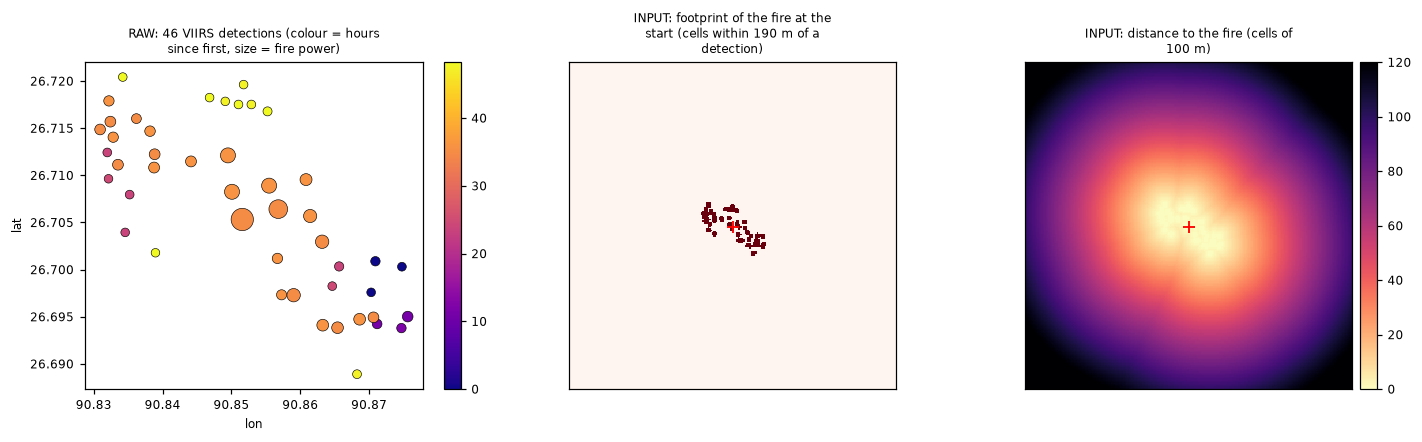

In [3]:
cp = pd.read_parquet(config.DATA / 'cases.parquet'); row = cp[(cp.event == meta['event']) & (cp.t0 == pd.Timestamp(meta['t0']))].iloc[0]
det = pd.read_parquet(config.DATA / 'detections' / f"{meta['year']}.parquet")
fire = det[(det.event == meta['event']) & (det.epoch <= int(row.epoch_from))]
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
h = (fire.t - fire.t.min()).dt.total_seconds() / 3600
sc = ax[0].scatter(fire.longitude, fire.latitude, c=h, s=30 + fire.frp * 3, cmap='plasma', edgecolor='k', lw=.4)
ax[0].set_title(f'RAW: {len(fire)} VIIRS detections (colour = hours since first, size = fire power)'); ax[0].set_xlabel('lon'); ax[0].set_ylabel('lat'); plt.colorbar(sc, ax=ax[0])
show(ax[1], c.seed_mask.astype(float), 'INPUT: footprint of the fire at the start (cells within 190 m of a detection)', 'Reds', cbar=False)
show(ax[2], np.minimum(c.dist_cells, 120), 'INPUT: distance to the fire (cells of 100 m)', 'magma_r')
plt.tight_layout(); plt.show()

## B. Land cover and forest land

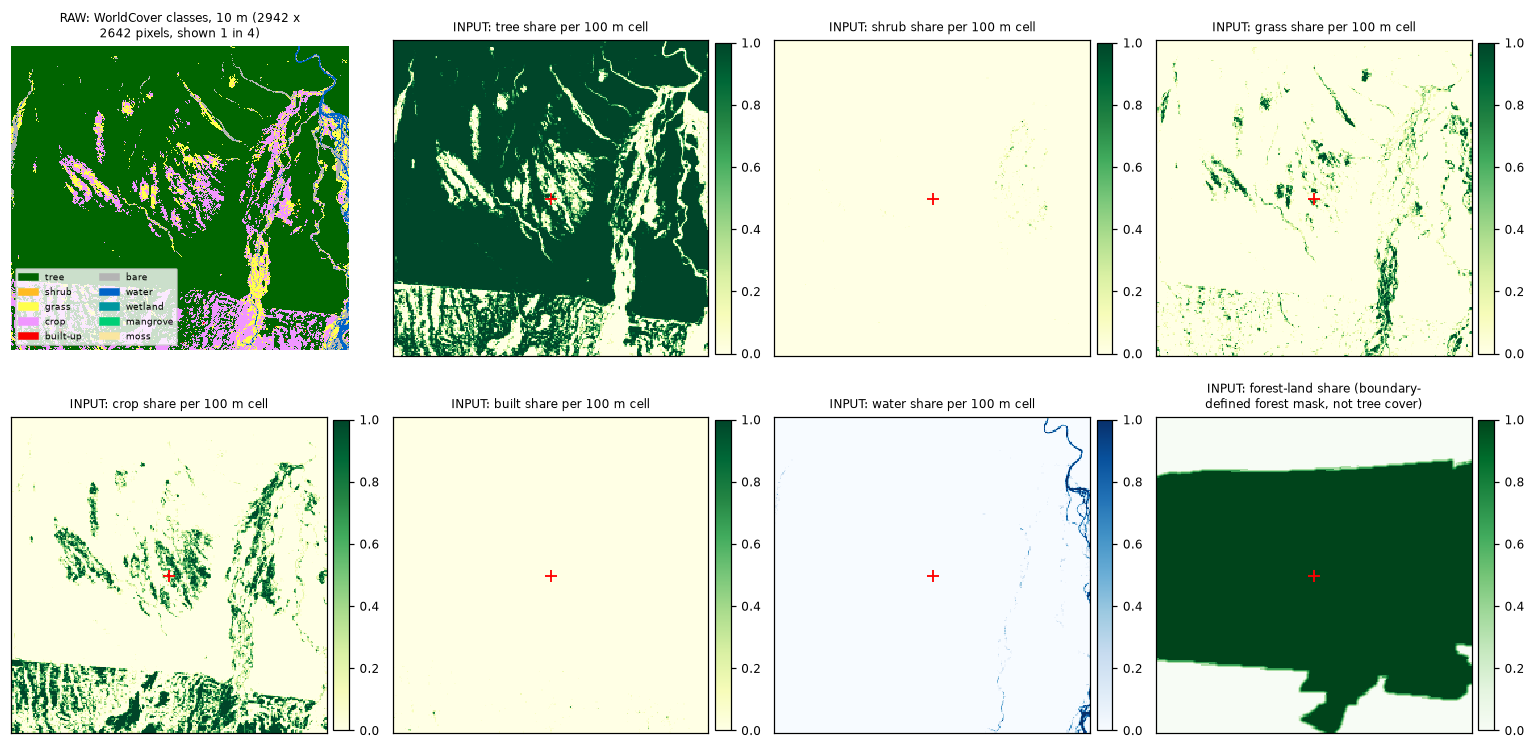

In [4]:
lat0, lon0 = meta['lat'], meta['lon']
tile = config.WORLDCOVER_DIR / f"ESA_WorldCover_10m_2021_v200_N{3*int(np.floor(lat0/3)):02d}E{3*int(np.floor(lon0/3)):03d}_Map.tif"
import rasterio
from rasterio.windows import from_bounds
w, s, e, n = grid.bounds_lonlat()
with rasterio.open(tile) as ds:
    raw = ds.read(1, window=from_bounds(w, s, e, n, ds.transform), boundless=True, fill_value=0)
classes = {10: ('tree', '#006400'), 20: ('shrub', '#ffbb22'), 30: ('grass', '#ffff4c'), 40: ('crop', '#f096ff'), 50: ('built-up', '#fa0000'), 60: ('bare', '#b4b4b4'), 80: ('water', '#0064c8'), 90: ('wetland', '#0096a0'), 95: ('mangrove', '#00cf75'), 100: ('moss', '#fae6a0')}
keys = sorted(classes); cm = ListedColormap(['#ffffff'] + [classes[k][1] for k in keys]); idxmap = {0: 0, **{k: i + 1 for i, k in enumerate(keys)}}
rawi = np.vectorize(lambda v: idxmap.get(int(v), 0))(raw[::4, ::4])
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
ax[0, 0].imshow(rawi, cmap=cm, vmin=0, vmax=len(keys), interpolation='nearest'); ax[0, 0].set_title(f'RAW: WorldCover classes, 10 m ({raw.shape[1]} x {raw.shape[0]} pixels, shown 1 in 4)'); ax[0, 0].axis('off')
ax[0, 0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=classes[k][1]) for k in keys], labels=[classes[k][0] for k in keys], fontsize=6, loc='lower left', ncol=2)
for a, k in zip(ax.ravel()[1:], ['lc_tree', 'lc_shrub', 'lc_grass', 'lc_crop', 'lc_built', 'lc_water']): show(a, env[k], f'INPUT: {k[3:]} share per 100 m cell', 'YlGn' if k != 'lc_water' else 'Blues', 0, 1)
show(ax[1, 3], env['forest_share'], 'INPUT: forest-land share (boundary-defined forest mask, not tree cover)', 'Greens', 0, 1)
plt.tight_layout(); plt.show()

## C. Terrain

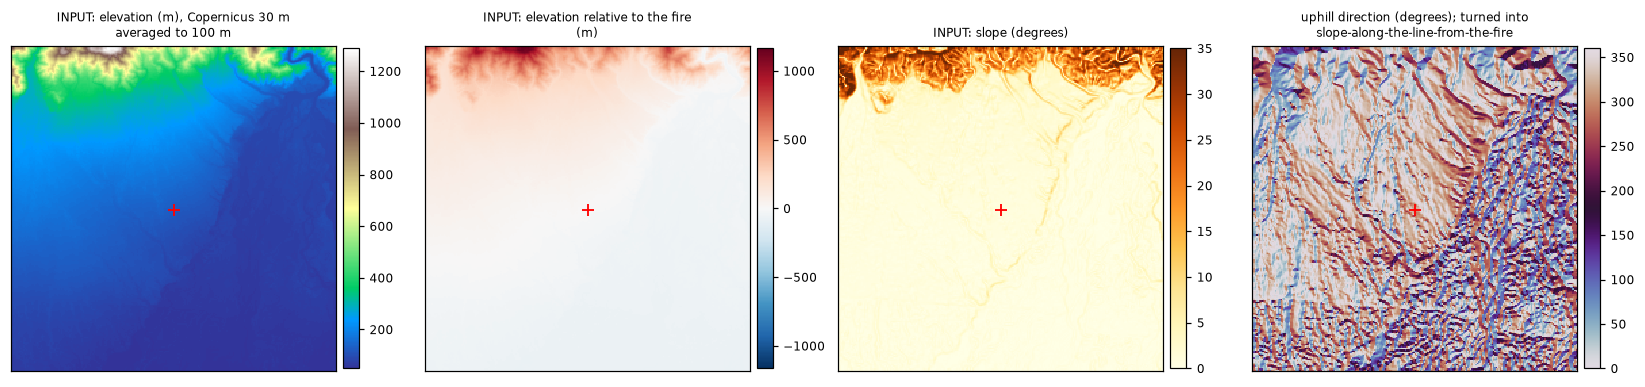

In [5]:
dem = env['dem']; rel = dem - np.nanmean(dem[c.seed_mask])
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
show(ax[0], dem, 'INPUT: elevation (m), Copernicus 30 m averaged to 100 m', 'terrain')
show(ax[1], rel, 'INPUT: elevation relative to the fire (m)', 'RdBu_r', -np.nanmax(np.abs(rel)), np.nanmax(np.abs(rel)))
show(ax[2], env['slope'], 'INPUT: slope (degrees)', 'YlOrBr', 0, 35)
show(ax[3], env['upslope'], 'uphill direction (degrees); turned into slope-along-the-line-from-the-fire', 'twilight', 0, 360)
plt.tight_layout(); plt.show()

## D. Greenness (MODIS NDVI) and dryness of the vegetation

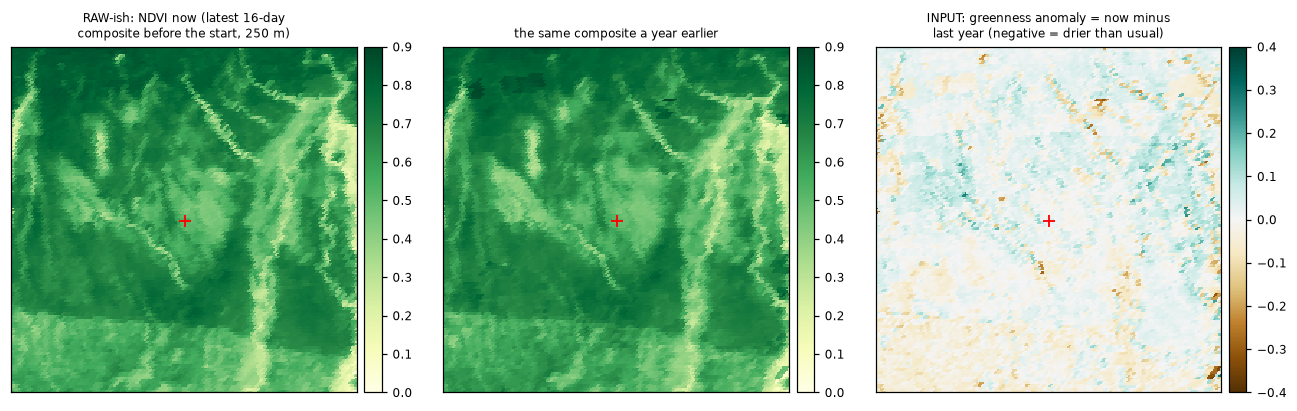

In [6]:
nd = np.load(d / 'ndvi.npz') if (d / 'ndvi.npz').exists() else None
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
if nd is not None:
    show(ax[0], nd['ndvi'], 'RAW-ish: NDVI now (latest 16-day composite before the start, 250 m)', 'YlGn', 0, 0.9)
    show(ax[1], nd['ndvi_prev'], 'the same composite a year earlier', 'YlGn', 0, 0.9)
    a = nd['ndvi'] - nd['ndvi_prev']; show(ax[2], a, 'INPUT: greenness anomaly = now minus last year (negative = drier than usual)', 'BrBG', -0.4, 0.4)
plt.tight_layout(); plt.show()

## E. Weather, dead-fuel moisture, rain history and soil

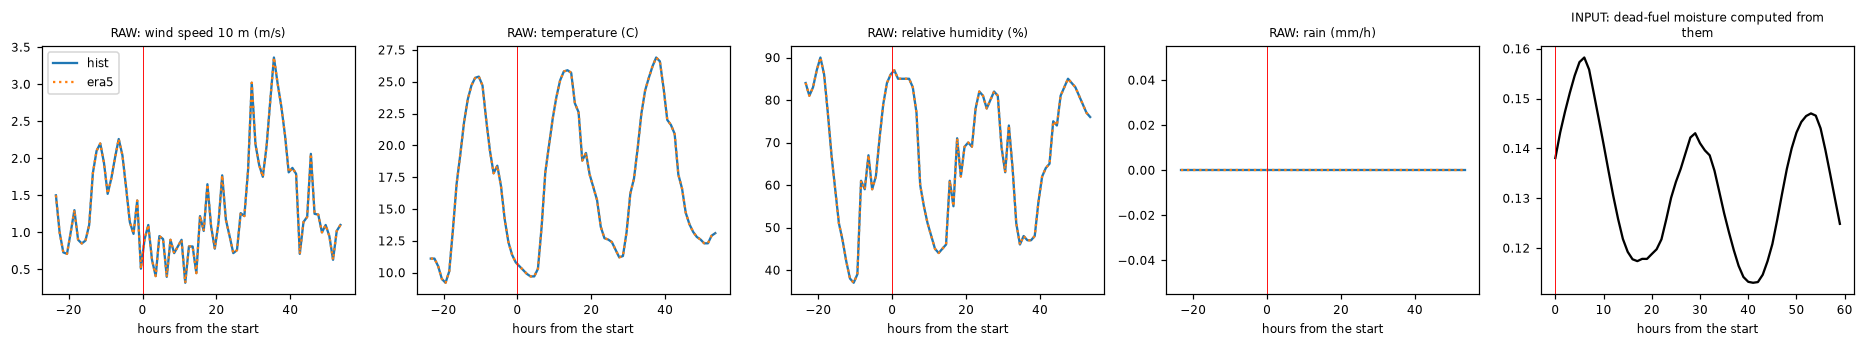

for this fire the two weather series (hist, era5) are identical, so the lines lie on top of each other
INPUTS (one number per fire, painted on the whole map):
rain7         19.90
rain30        26.40
rain60        35.30
days_dry       1.00
balance30    -46.06
tmax14        24.43
rh14          73.07
sm7            0.14
sm28           0.09
sm7_change     0.04
vpd3           0.61
wind is computed but NOT given to the final models: it added nothing in every test.


In [7]:
wx = pd.read_csv(d / 'weather.csv', parse_dates=['time']); H = 48
fig, ax = plt.subplots(1, 5, figsize=(17, 3.2))
for src, st in (('hist', '-'), ('era5', ':')):
    w_ = wx[(wx.source == src) & (wx.hours_from_t0.between(-24, H + 6))]
    ax[0].plot(w_.hours_from_t0, w_.wind_speed_10m, st, label=src); ax[1].plot(w_.hours_from_t0, w_.temperature_2m, st); ax[2].plot(w_.hours_from_t0, w_.relative_humidity_2m, st); ax[3].plot(w_.hours_from_t0, w_.precipitation, st)
hrs = np.arange(len(c.moisture)); ax[4].plot(hrs, c.moisture, 'k');
for a, t_ in zip(ax, ['RAW: wind speed 10 m (m/s)', 'RAW: temperature (C)', 'RAW: relative humidity (%)', 'RAW: rain (mm/h)', 'INPUT: dead-fuel moisture computed from them']): a.set_title(t_); a.set_xlabel('hours from the start'); a.axvline(0, color='r', lw=.6)
ax[0].legend(); plt.tight_layout(); plt.show()
j = wx[wx.source == 'hist'].set_index('hours_from_t0').index.intersection(wx[wx.source == 'era5'].set_index('hours_from_t0').index)
if np.allclose(wx[wx.source == 'hist'].set_index('hours_from_t0').loc[j, 'temperature_2m'], wx[wx.source == 'era5'].set_index('hours_from_t0').loc[j, 'temperature_2m']): print('for this fire the two weather series (hist, era5) are identical, so the lines lie on top of each other')
ant = json.load(open(d / 'ant.json')) if (d / 'ant.json').exists() else None
antt = pd.read_parquet(config.DATA / 'antecedent.parquet').set_index('case'); sl = pd.read_parquet(config.DATA / 'soil.parquet').set_index('case')
print('INPUTS (one number per fire, painted on the whole map):'); print(pd.concat([antt.loc[CASE], sl.loc[CASE]]).round(2).to_string())
print('wind is computed but NOT given to the final models: it added nothing in every test.')

## F. Roads, rivers and people

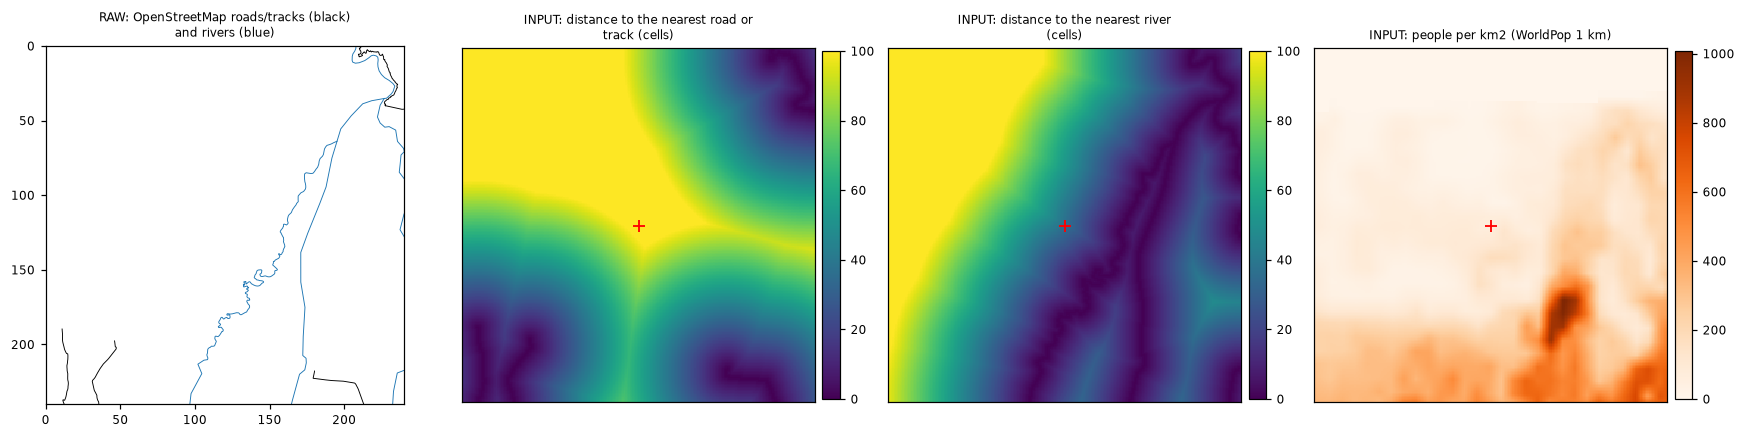

In [8]:
tiles = ancillary.tiles_of(grid)
lines = ancillary.load_lines(config.DATA / 'osm_lines.geojsonseq', tiles)
from pyproj import Transformer
tf = Transformer.from_crs(4326, grid.epsg, always_xy=True)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for kind, col in (('road', 'k'), ('river', 'tab:blue')):
    for k, xy in lines:
        if k == kind:
            x, y = tf.transform(xy[:, 0], xy[:, 1]); ax[0].plot((np.array(x) - grid.x0) / grid.res, (grid.y0 - np.array(y)) / grid.res, col, lw=.6)
ax[0].set_xlim(0, grid.nx); ax[0].set_ylim(grid.ny, 0); ax[0].set_title('RAW: OpenStreetMap roads/tracks (black) and rivers (blue)'); ax[0].set_aspect('equal')
osm = np.load(d / 'osm.npz'); pop = np.load(d / 'pop.npz')['pop']
show(ax[1], osm['road_dist'], 'INPUT: distance to the nearest road or track (cells)', 'viridis', 0, 100)
show(ax[2], osm['river_dist'], 'INPUT: distance to the nearest river (cells)', 'viridis', 0, 100)
show(ax[3], pop, 'INPUT: people per km2 (WorldPop 1 km)', 'Oranges')
plt.tight_layout(); plt.show()

## G. The truth: which cells burned

Shown here for the two-day window (the day-level burn date cannot separate the first day from the second). The models learn the first-day cells, which are a subset of these; the counts in section H are for the central 192 x 192 crop.

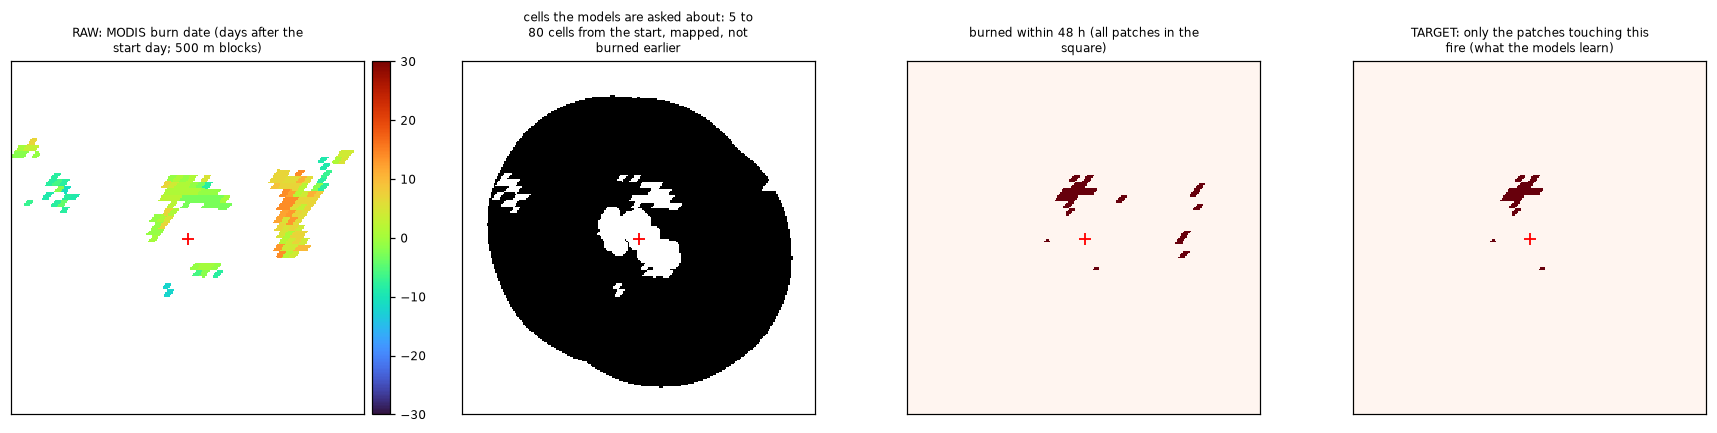

burned cells in the target: 312 of 29364 asked about (1.1 %)


In [9]:
b = np.load(d / 'burn_long.npz'); doy = b['doy'].astype(float); t0 = pd.Timestamp(meta['t0']); d0 = t0.timetuple().tm_yday
c48 = __import__('dataclasses').replace(c, meta={**c.meta, 't1': str(t0 + pd.Timedelta(hours=48))})
truth, cand, ok = burn_eval.burn_masks(c48, b['doy'], int(b['year'])); truth_c, cand_c = burn_eval.connected_truth(c48, truth, cand)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
dd = np.where(doy > 0, doy - d0, np.nan); show(ax[0], dd, 'RAW: MODIS burn date (days after the start day; 500 m blocks)', 'turbo', -30, 30)
show(ax[1], cand_c.astype(float), 'cells the models are asked about: 5 to 80 cells from the start, mapped, not burned earlier', 'Greys', cbar=False)
show(ax[2], truth.astype(float), 'burned within 48 h (all patches in the square)', 'Reds', cbar=False)
show(ax[3], truth_c.astype(float), 'TARGET: only the patches touching this fire (what the models learn)', 'Reds', cbar=False)
plt.tight_layout(); plt.show()
print(f'burned cells in the target: {int(truth_c.sum())} of {int(cand_c.sum())} asked about ({100*truth_c.sum()/cand_c.sum():.1f} %)')

## H. Everything the models see: 46 layers and 31 numbers

In [10]:
import importlib.util, torch
from pathlib import Path
ROOT = Path('..').resolve(); SC = ROOT / 'scripts'
spec = importlib.util.spec_from_file_location('tr', SC / '61_train.py'); sys_argv = sys.argv; sys.argv = sys.argv[:1]
tr = importlib.util.module_from_spec(spec); spec.loader.exec_module(tr); sys.argv = sys_argv
REL = ROOT / 'release/fire_spread_dataset'; D = tr.Data([str(REL / f'part_p{k}') for k in range(6)], 24)
CK = torch.load(ROOT.parent / 'paper_fire_spread/results/models/fsn_24_s0.pt', weights_only=False, map_location='cpu')
row = int(np.flatnonzero(D.meta.case.values == CASE)[0])
X_raw, S_raw, Y, CAND, DIST = D.raw(row)          # as stored: 46 layers of 192 x 192, 31 numbers
sp_names, sc_names = D.sp_names, D.sc_names
print(f'fire {CASE}: {X_raw.shape[0]} picture layers of {X_raw.shape[1]} x {X_raw.shape[2]} cells, {len(S_raw)} numbers')

fire 2023-089376_4: 46 picture layers of 192 x 192 cells, 31 numbers


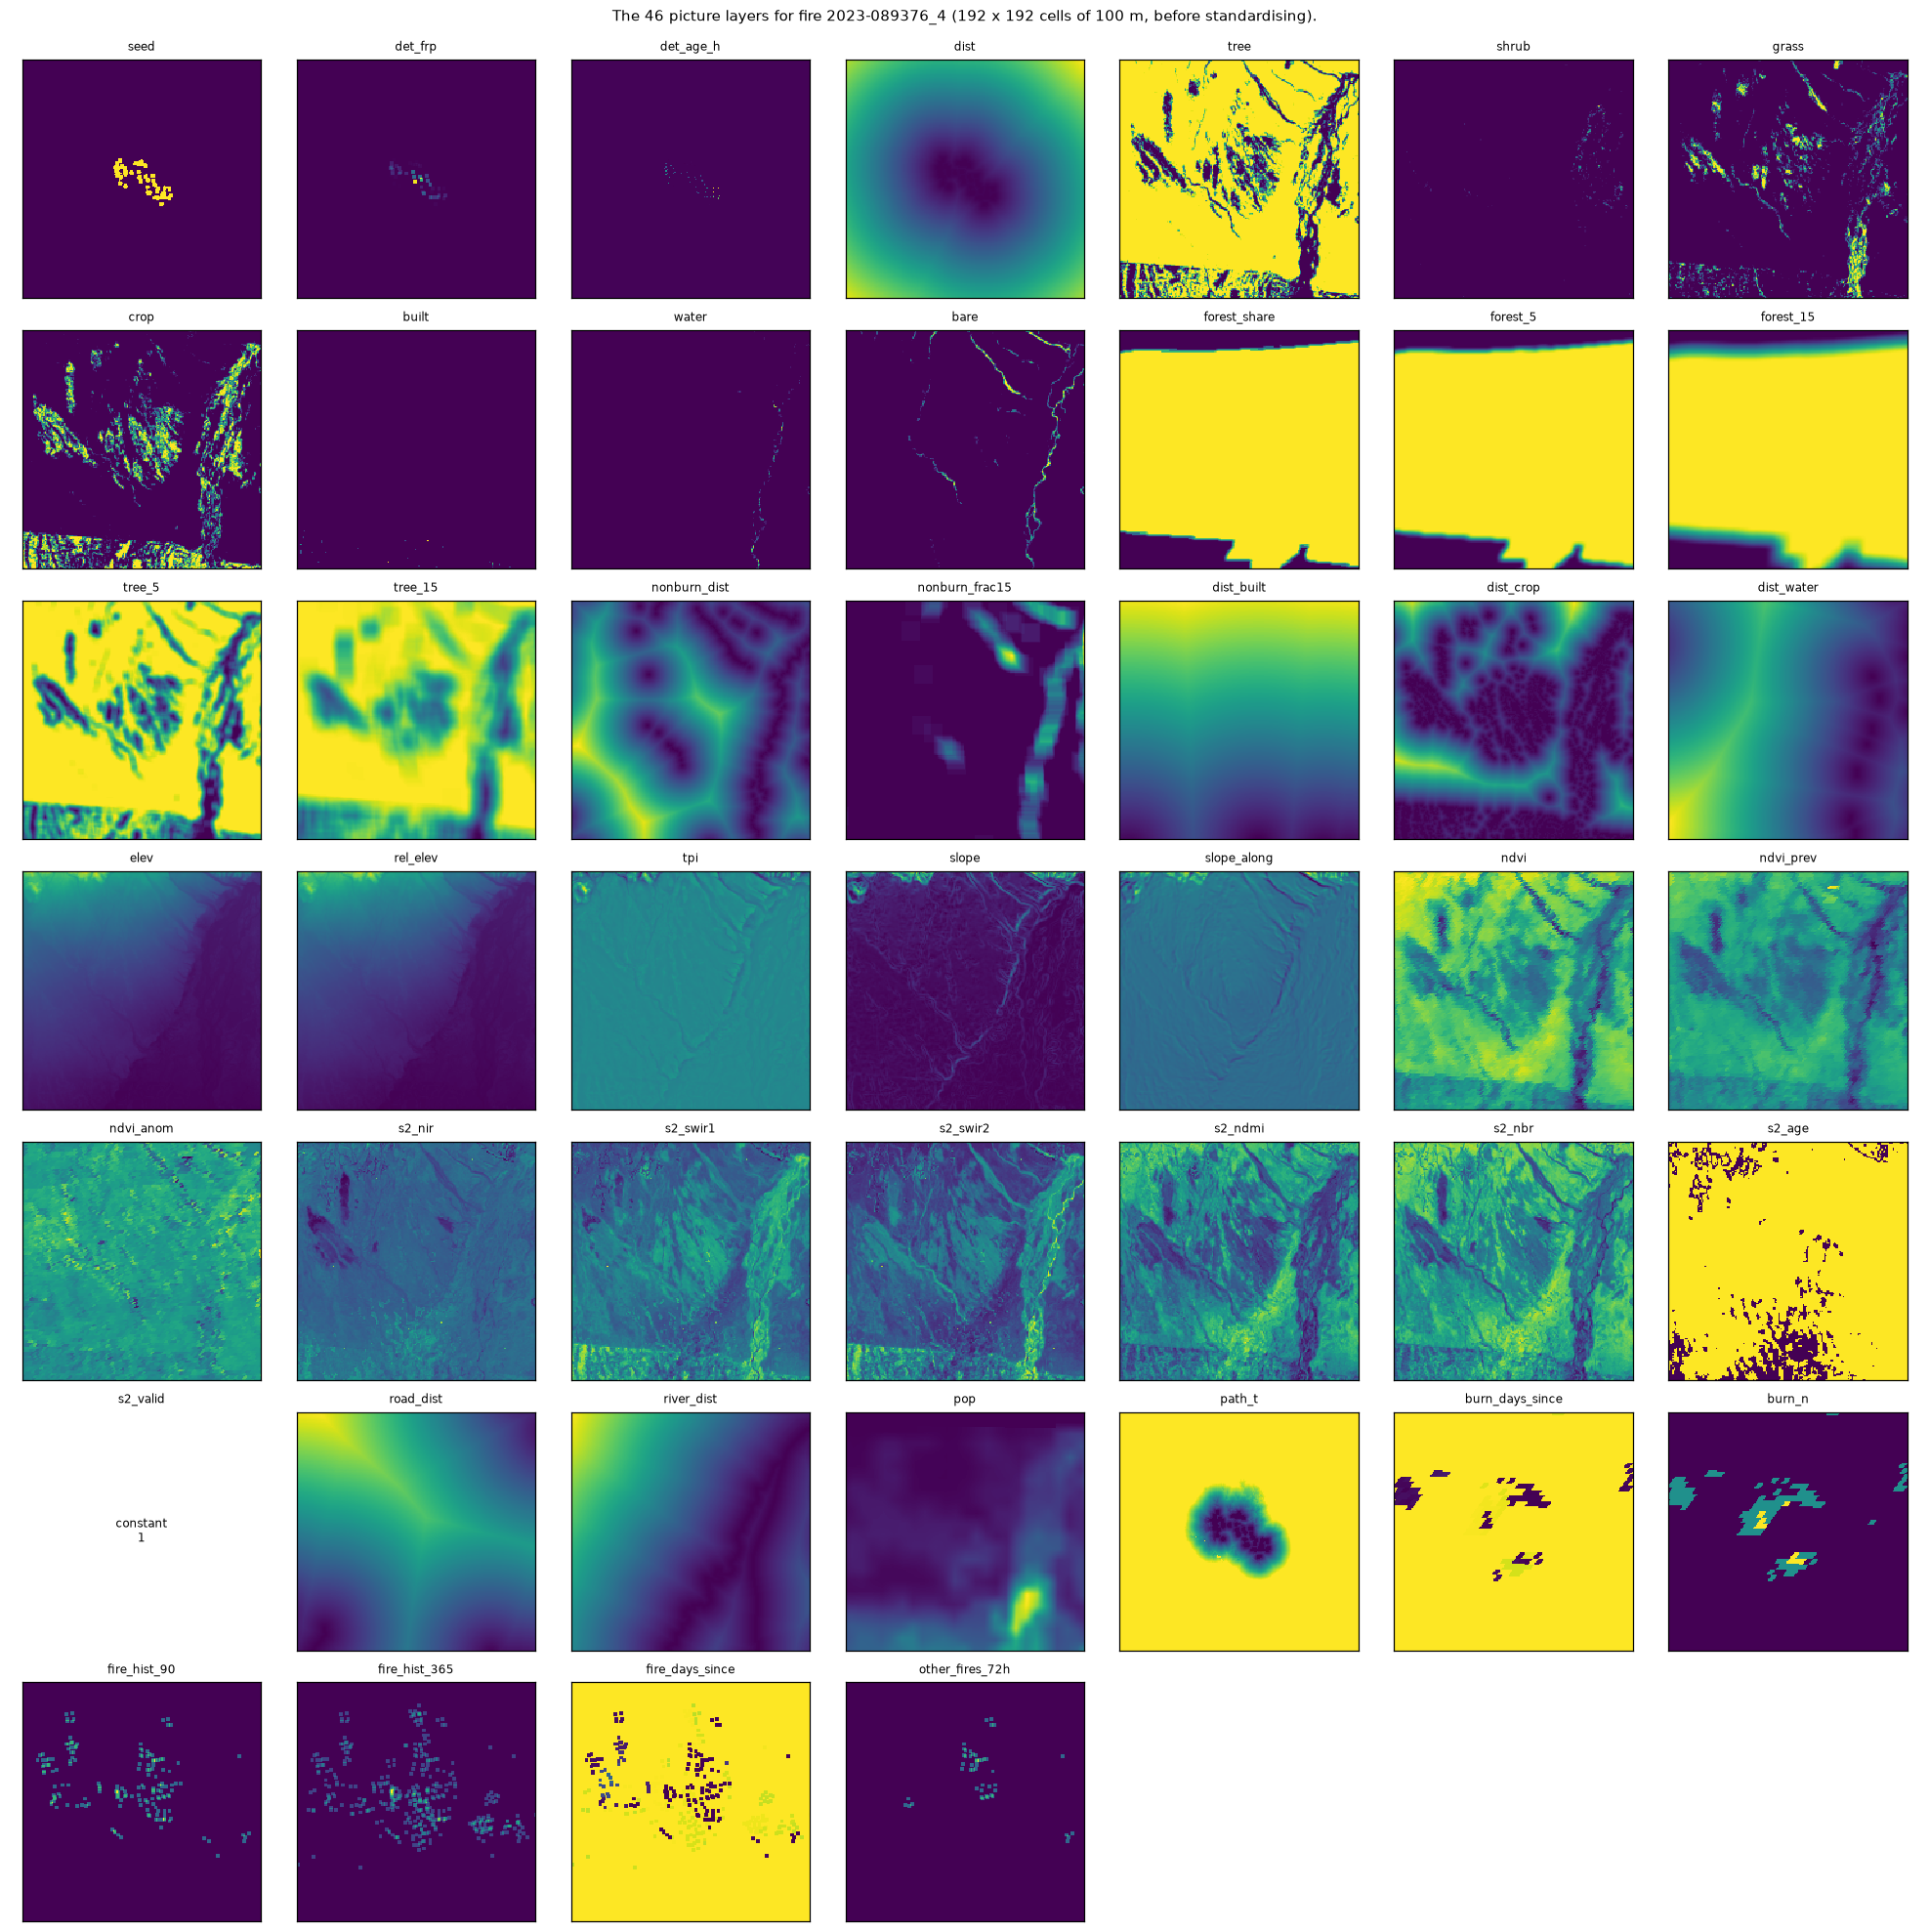

the 31 numbers (one per fire, not a picture):
n_start         3.850000
frp_sum_log     5.896000
extent_km       7.062000
act5            3.611000
act20           3.912000
act_ev20        2.079000
month_sin       0.866000
month_cos       0.500000
doy_sin         0.699000
doy_cos         0.715000
hour_sin        0.380000
hour_cos        0.925000
temp_mean      17.485001
temp_max       25.844999
rh_mean        66.675003
rh_min         44.448002
vpd_max         1.850000
rain_sum        0.000000
moist_mean      0.135000
moist_min       0.117000
rain7          19.900000
rain30         26.400000
rain60         35.299999
days_dry        1.000000
balance30     -46.060001
tmax14         24.429001
rh14           73.070999
sm7             0.138000
sm28            0.094000
sm7_change      0.042000
vpd3            0.610000
target: 312 burned cells among 28426 asked about, same crop


In [11]:
fig, axs = plt.subplots(7, 7, figsize=(18, 18))
for i, (a, nm) in enumerate(zip(axs.ravel(), sp_names)):
    v = X_raw[i].astype(np.float32)
    if np.nanstd(v) < 1e-6: a.text(.5, .5, f'constant\n{np.nanmean(v):.3g}', ha='center', va='center'); a.set_title(nm); a.axis('off'); continue
    a.imshow(v, cmap='viridis', interpolation='nearest'); a.set_title(nm); a.set_xticks([]); a.set_yticks([])
for a in axs.ravel()[len(sp_names):]: a.axis('off')
plt.suptitle(f'The {len(sp_names)} picture layers for fire {CASE} (192 x 192 cells of 100 m, before standardising).', y=.995)
plt.tight_layout(); plt.show()
print('the', len(sc_names), 'numbers (one per fire, not a picture):'); print(pd.Series(S_raw, index=sc_names).round(3).to_string())
print(f'target: {int(Y.sum())} burned cells among {int(CAND.sum())} asked about, same crop')

## I. What the model is actually given

Two things go in, one comes out:

* **a 46 x 192 x 192 array**: the 46 picture layers, each standardised with the mean and spread of the training fires; a missing value (for example a cell with no cloud-free Sentinel-2 view) becomes 0;
* **31 numbers** for the fire as a whole (weather, fire size, season, rain history), standardised the same way;
* **out:** a 192 x 192 map of scores, one per cell. Only the cells asked about are scored.

model input 1 (pictures): (46, 192, 192) float32 | mean 0.15, std 0.98, share of exact zeros 0.0%
model input 2 (numbers):  (31,) float32


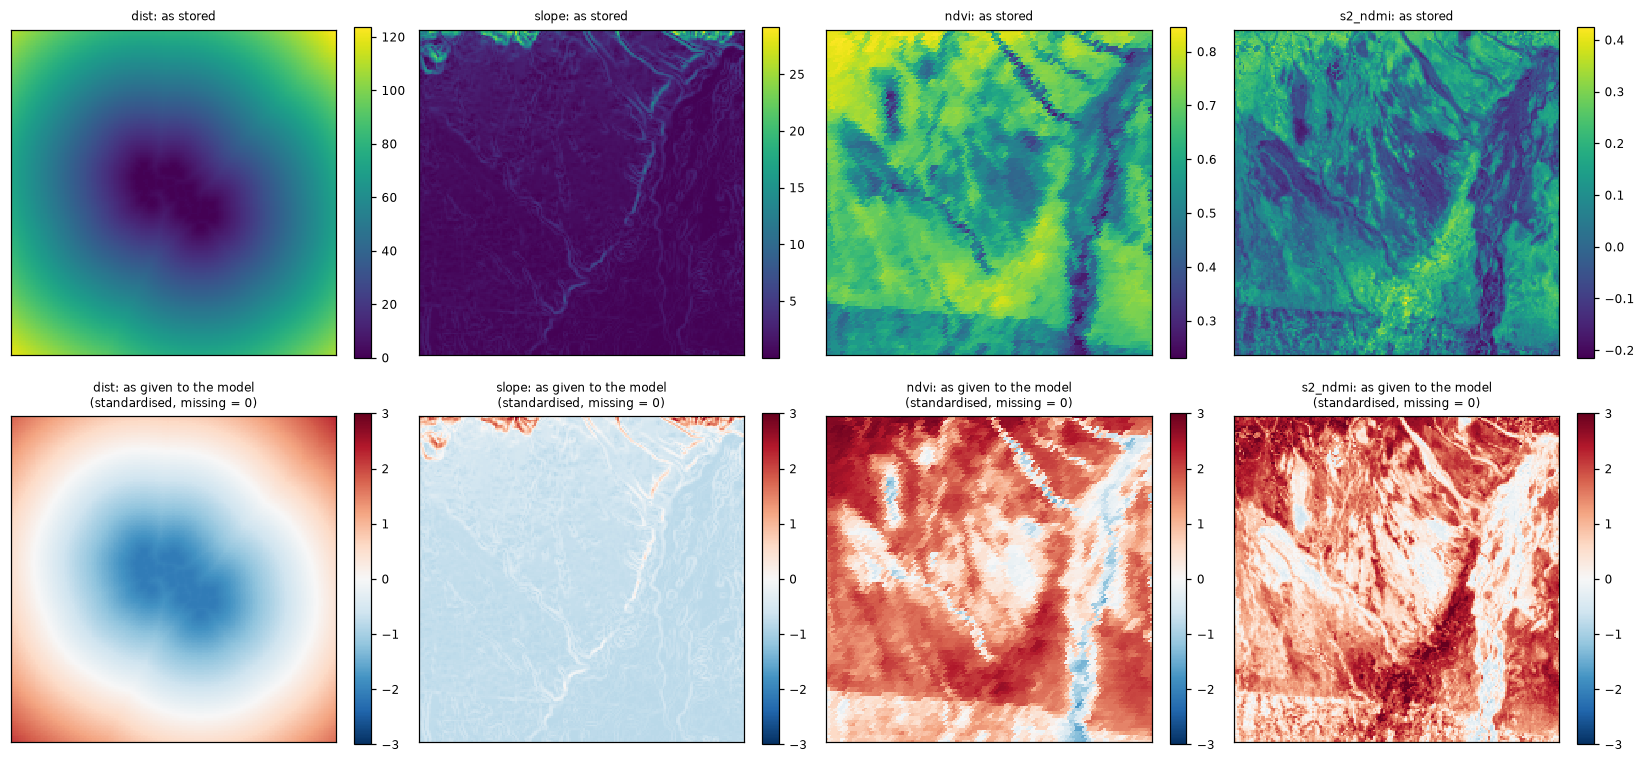

In [12]:
D.mu, D.sd, D.smu, D.ssd = CK['mu'], CK['sd'], CK['smu'], CK['ssd']
x, s, y, cand, dist = D.get(row)
print('model input 1 (pictures):', x.shape, x.dtype, f'| mean {x.mean():.2f}, std {x.std():.2f}, share of exact zeros {np.mean(x == 0):.1%}')
print('model input 2 (numbers): ', s.shape, s.dtype)
show_l = ['dist', 'slope', 'ndvi', 's2_ndmi']
fig, ax = plt.subplots(2, 4, figsize=(15, 7))
for k, nm in enumerate(show_l):
    j = sp_names.index(nm); r = X_raw[j].astype(np.float32)
    im0 = ax[0, k].imshow(r, cmap='viridis', interpolation='nearest'); ax[0, k].set_title(f'{nm}: as stored (white = missing)' if np.isnan(r).any() else f'{nm}: as stored'); plt.colorbar(im0, ax=ax[0, k], fraction=.046)
    im1 = ax[1, k].imshow(x[j], cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest'); ax[1, k].set_title(f'{nm}: as given to the model (standardised, missing = 0)'); plt.colorbar(im1, ax=ax[1, k], fraction=.046)
    for a in ax[:, k]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

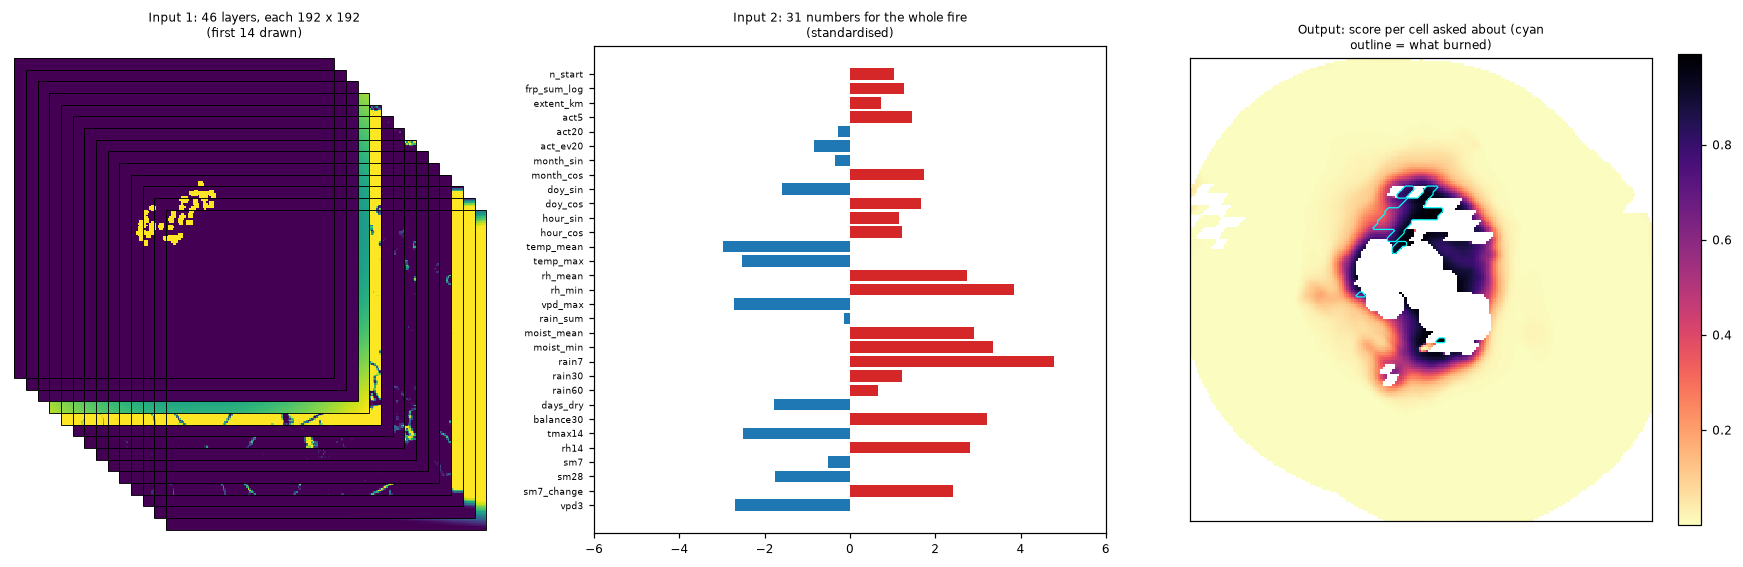

In [13]:
from firespread import imgmodels
m = imgmodels.make('firesensenet', len(CK['sp_names']), len(CK['sc_names']), pretrained=False); m.load_state_dict(CK['model']); m.eval()
with torch.no_grad(): score = torch.sigmoid(m(torch.from_numpy(x)[None], torch.from_numpy(s)[None]))[0].numpy()
fig = plt.figure(figsize=(16, 5.2)); ax = [fig.add_subplot(1, 3, k + 1) for k in range(3)]
n_show, off = 14, 7
for k in reversed(range(n_show)):
    ax[0].imshow(x[k], cmap='viridis', extent=(k * off, k * off + 192, 192 + (n_show - 1 - k) * off, (n_show - 1 - k) * off), interpolation='nearest'); ax[0].add_patch(plt.Rectangle((k * off, (n_show - 1 - k) * off), 192, 192, fill=False, ec='k', lw=.6))
ax[0].set_xlim(-2, 192 + n_show * off); ax[0].set_ylim(-2, 192 + n_show * off); ax[0].set_aspect('equal'); ax[0].axis('off')
ax[0].set_title(f'Input 1: {x.shape[0]} layers, each 192 x 192 (first {n_show} drawn)')
ax[1].barh(range(len(s)), s, color=np.where(s >= 0, 'tab:red', 'tab:blue')); ax[1].set_yticks(range(len(s))); ax[1].set_yticklabels(sc_names, fontsize=6); ax[1].invert_yaxis(); ax[1].set_xlim(-6, 6)
ax[1].set_title(f'Input 2: {len(s)} numbers for the whole fire (standardised)')
sc_map = np.where(cand > 0, score, np.nan); im = ax[2].imshow(sc_map, cmap='magma_r', interpolation='nearest'); plt.colorbar(im, ax=ax[2], fraction=.046)
ax[2].contour(y > 0, levels=[.5], colors='cyan', linewidths=.8); ax[2].set_xticks([]); ax[2].set_yticks([])
ax[2].set_title('Output: score per cell asked about (cyan outline = what burned)')
plt.tight_layout(); plt.show()

## What the models receive

* **Input:** a 46 x 192 x 192 array per fire (the layers above) and 31 numbers; each is standardised with the training fires' mean and spread, and missing values (for example, no cloud-free view) become 0.
* **Target:** the 192 x 192 map of cells that burned in the next day (section G also shows the two-day version; the burned-area product dates burning only to the day).
* **Scored only on** the cells asked about, with the burned patches that touch the fire.
* **Tree models** see the same layers one cell at a time; **image models** see the whole square at once.
* Wind is deliberately left out of the final models, because it added nothing in any test.